## Dataset and DataLoader

In [2]:
import os 
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class CelebADataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir=img_dir
        # Getting all the image file names
        self.img_names = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        self.transform = transform

    def __len__(self):
        return len(self.img_names)
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_names[idx])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image

data_dir = '/kaggle/input/datasets/abhinandanm1/celeba/img_align_celeba'
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])
dataset = CelebADataset(img_dir = data_dir, transform = transform)
print(len(dataset))

202599


In [3]:
# We don't need 202599 data for this little work
# We'll take 8000 images for training and 1000 for validation, testing for this work

from torch.utils.data import Subset
import numpy as np

dataset = CelebADataset(img_dir = data_dir, transform = transform)
train_size=8000
val_size=1000

# We'll take random data's for much generalization
indices = np.random.permutation(len(dataset))
train_indices = indices[:train_size]
val_indices = indices[train_size : train_size + val_size]

train_subset = Subset(dataset, train_indices)
val_subset = Subset(dataset, val_indices)

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(val_subset, batch_size=32, shuffle = False, num_workers=2, pin_memory = True)


Batch tensor shape: torch.Size([32, 3, 128, 128])


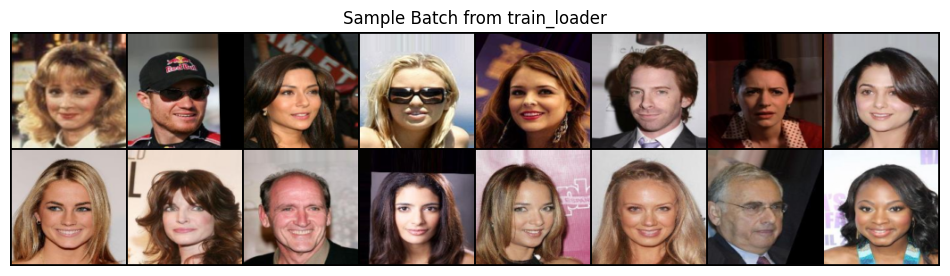

In [4]:
# A quick visualization
import matplotlib.pyplot as plt
import torchvision
import torch

dataiter = iter(train_loader)
images = next(dataiter)
print(f"Batch tensor shape: {images.shape}")

# If you used Normalization like transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
# un-normalize them back to [0, 1] range for proper visualization
images = images * 0.5 + 0.5
grid = torchvision.utils.make_grid(images[:16], nrow=8)
# Convert tensor to numpy and transpose dimensions from (C, H, W) to (H, W, C)
plt.figure(figsize=(12, 6))
plt.imshow(grid.numpy().transpose((1, 2, 0)))
plt.axis('off')
plt.title("Sample Batch from train_loader")
plt.show()

## Masking
There are three types of masking has been used in **Context Encoders** papers, *central region mask*, *random block mask*, *random region mask*.

In [5]:
# In region mask, there are
# 1. central region, 2. random block, 3. random region
import numpy as np

# Central region masking
def mask_central(rng, B, H=128, W=128):
  # rng here is random number generator, primarily for reproduciability, mainly used for random block and random region
  # Fixed central sqaure masking approx 25% of the image
  m=np.zeros((B,H,W), dtype=np.float32)
  h,w = H//2, W//2
  y,x = (H-h)//2, (W-w)//2
  m[:, y:y+h, x:x+w]=1.0 # masking status
  return m

def mask_block(rng, B, H=128, W=128, max_cover=None):
  # Here multiple blocks has been removed from the image of 1/4th image
  if max_cover is None:
    max_cover = (H * W)//4
  m = np.zeros((B,H,W), dtype=np.float32)
  for b in range(B):
        for _ in range(int(rng.integers(3, 7))):
            # Rectangle dimensions scale with image size.
            h = int(rng.integers(max(2, H // 32), max(3, H // 8)))
            w = int(rng.integers(max(2, W // 32), max(3, W // 8)))

            y = int(rng.integers(0, H - h + 1))
            x = int(rng.integers(0, W - w + 1))

            # Do not exceed the coverage budget.
            candidate = m[b].copy()
            candidate[y:y+h, x:x+w] = 1.0

            if candidate.sum() <= max_cover:
                m[b] = candidate
  return m

def mask_region(rng, B, H=128, W=128, max_cover=None):
    if max_cover is None:
        max_cover = (H * W) // 4
    m = np.zeros((B, H, W), dtype=np.float32)
    brush = max(3, min(H, W) // 32)

    for b in range(B):
        target = int(rng.integers(max(1, max_cover // 2), max_cover + 1))
        y = int(rng.integers(0, H)); x = int(rng.integers(0, W))
        covered = 0
        for _ in range(H * W * 2):
            y0, y1 = max(0, y - brush // 2), min(H, y + brush // 2 + 1)
            x0, x1 = max(0, x - brush // 2), min(W, x + brush // 2 + 1)
            patch = m[b, y0:y1, x0:x1]                 # view into m
            added = int((patch == 0).sum())            # newly covered pixels
            if covered + added <= max_cover:
                patch[:] = 1.0
                covered += added
                if covered >= target:
                    break
            # random-walk step runs every iteration
            y = int(np.clip(y + rng.integers(-brush, brush + 1), 0, H - 1))
            x = int(np.clip(x + rng.integers(-brush, brush + 1), 0, W - 1))
    return m

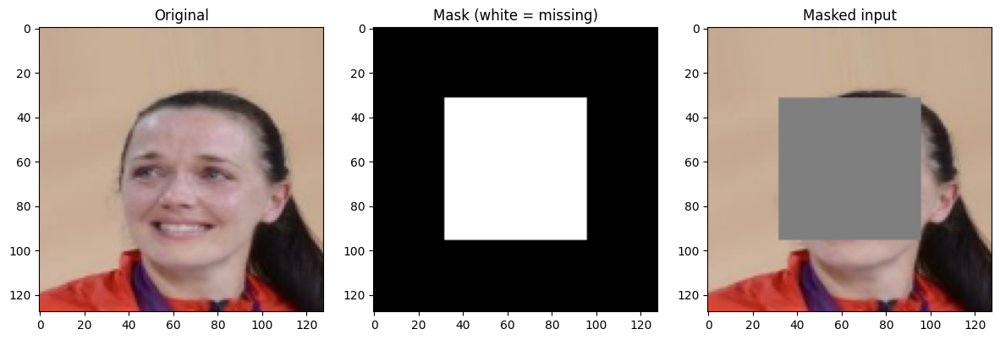

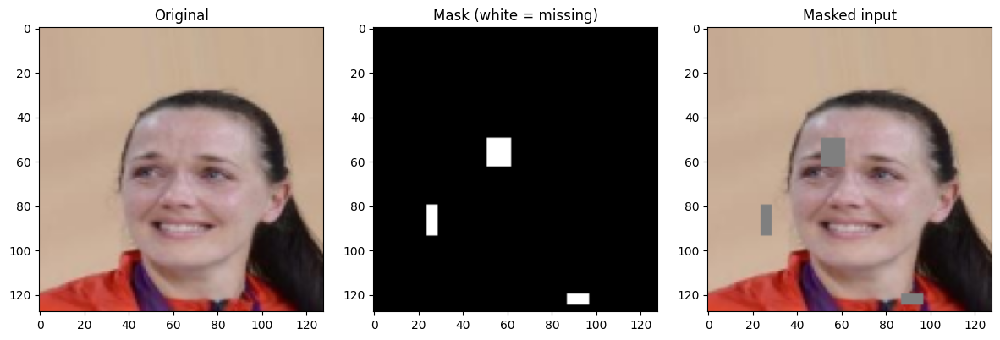

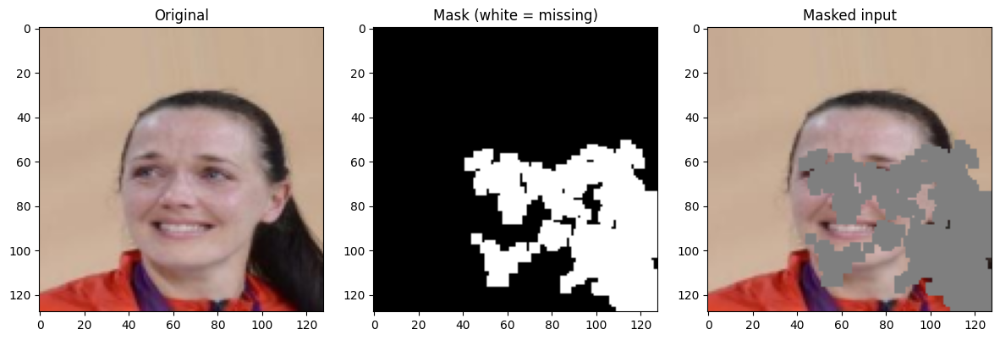

In [6]:
# Quick sanity check of masking
import matplotlib.pyplot as plt
rng=np.random.default_rng(42)

images=next(iter(train_loader))
B,C,H,W = images.shape
mask_functions={"Central":mask_central, "Block":mask_block, "Random region":mask_region}

# Applying masks
for k,v in mask_functions.items():
  masks=mask_functions[k](rng, B, H, W)
  mask_tensor = torch.from_numpy(masks).unsqueeze(1)
  masked_images = images*(1.0 - mask_tensor)

  # Visualize the first image.
  fig, ax = plt.subplots(1, 3, figsize=(12, 4))

  original = images[0].permute(1, 2, 0).numpy()
  masked = masked_images[0].permute(1, 2, 0).numpy()

  ax[0].imshow(np.clip(original * 0.5 + 0.5, 0, 1))
  ax[0].set_title("Original")

  ax[1].imshow(masks[0], cmap="gray", vmin=0, vmax=1)
  ax[1].set_title("Mask (white = missing)")

  ax[2].imshow(np.clip(masked * 0.5 + 0.5, 0, 1))
  ax[2].set_title("Masked input")

  plt.tight_layout()
  plt.show()

## Encoder-Decoder

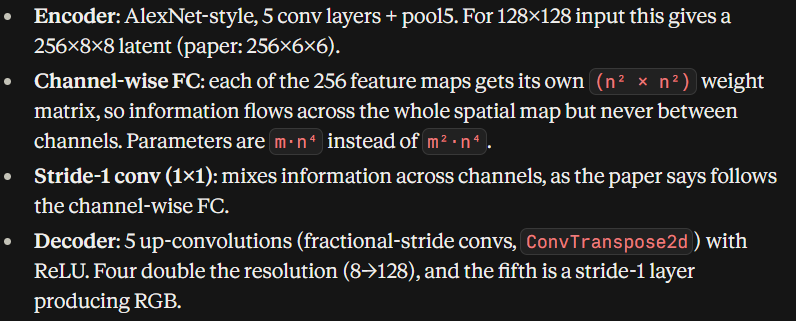

In [7]:
import torch
import torch.nn as nn 

# Encoder is AlexNet style
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        """
        block() helper function creates a standard convolution block containing
        nn.Conv2d: A 2D convolution layer with custon input channel (cin),
                   output channel (cout), kernel size (k), stride (s), padding (p).
                   bias = False is used because it is immediately followed by BatchNorm2d (which handles bias naively).

        nn.BatchNorm2d: Normalizes the layer activations to stabilize and speed up training. 
        """
        def block(cin, cout, k, s, p):
            return nn.Sequential(
                nn.Conv2d(cin, cout, k, s, p, bias=False),
                nn.BatchNorm2d(cout),
                nn.LeakyReLU(0.2, inplace=True))
        """
        self.net: Is a modified AlexNet style convolutional network. It progressively downsamples
                  input images (128x128 to 8x8 feature maps with 256 channels) through
                  alternating convolutions and max-pooling layers.
        """
        self.net = nn.Sequential(
            block(3,   64,  7, 2, 3),            # 128 -> 64
            nn.MaxPool2d(3, 2, 1),               # 64  -> 32
            block(64,  192, 5, 1, 2),            # 32
            nn.MaxPool2d(3, 2, 1),               # 32  -> 16
            block(192, 384, 3, 1, 1),            # 16
            block(384, 256, 3, 1, 1),            # 16
            block(256, 256, 3, 1, 1),            # 16  (conv5)
            nn.MaxPool2d(3, 2, 1),               # 16  -> 8  (pool5)
        )

    def forward(self, x):
        return self.net(x)

"""
Channel wise fully connected layer is a purely convolutional layer only propagate local context.
To fill in missing image patches, information from one corner of an image needs to connect to another. 
A standard fully-connected layer would do this, but it would cause a massive explosion in parameters (over 100 million). 
To fix this, the authors introduced a channel-wise fully-connected layer.
"""
class ChannelWiseFC(nn.Module):
    """Fully-connected layer with groups = channels.
    Input/Output: (B, m, n, n). Params: m * n^4 (+ m * n^2 bias)."""
    """
    self.m is the number of feature maps (channels, e.g., 256)
    self.n2 is the flattened spatial size (8x8 = 64)
    self.weight creates a tensor of shape (256, 64, 64). 
    """
    def __init__(self, channels, size):
        super().__init__()
        self.m, self.n2 = channels, size * size
        self.weight = nn.Parameter(torch.empty(channels, self.n2, self.n2))
        self.bias = nn.Parameter(torch.zeros(channels, self.n2))
        bound = 1 / self.n2 ** 0.5          # same scheme as nn.Linear
        nn.init.uniform_(self.weight, -bound, bound)

    def forward(self, x):
        B, m, n, _ = x.shape
        x = x.reshape(B, m, self.n2)                       # flatten each feature map
        x = torch.einsum('bmi,mij->bmj', x, self.weight)   # per-channel FC
        x = x + self.bias
        return x.reshape(B, m, n, n)

# The decoder takes the processed features and scales them back up to generate the final pixel values for the missing regions.
class Decoder(nn.Module):
    """Channel-wise FC -> 1x1 conv -> 5 up-convolutions. 256x8x8 -> 3x128x128."""
    """
    self.cw_fc first passes the bottleneck (compact representation) through 
    the channel wise fully connected layer to propagate spatial context.

    Because the channel wise fully connected layer only operates within individual channels, a 1x1 convolution
    layer is used right after to mix information across different channels. 
    """
    def __init__(self, channels=256, size=8):
        super().__init__()
        self.cw_fc = ChannelWiseFC(channels, size)
        self.mix = nn.Conv2d(channels, channels, 1)       # stride-1 conv across channels

        # up is for upsampling
        def up(cin, cout):                                # fractional-stride conv (x2)
            return nn.Sequential(
                nn.ConvTranspose2d(cin, cout, 4, 2, 1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True))
        self.up = nn.Sequential(
            up(256, 128),                                 # 8   -> 16
            up(128, 64),                                  # 16  -> 32
            up(64, 64),                                   # 32  -> 64
            up(64, 32),                                   # 64  -> 128
            nn.ConvTranspose2d(32, 3, 3, 1, 1),           # 5th up-conv, stride 1 -> RGB
            nn.Tanh(),                                    # matches [-1, 1] normalization
        )
    def forward(self, z):
        z = self.mix(self.cw_fc(z))
        return self.up(z)

class ContextEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()

    def forward(self, masked_img):
        return self.decoder(self.encoder(masked_img))
        

In [8]:
# Quick sanity check
import torch
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
model = ContextEncoder().to(device)
rng = np.random.default_rng(50)

images = next(iter(train_loader))
img = images.to(device)
mask = torch.from_numpy(mask_central(rng, img.size(0))).unsqueeze(1).to(device)
masked_input = img*(1-mask)
out = model(masked_input)
print(out.shape)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M params")


torch.Size([32, 3, 128, 128])
4.343171 M params


## Reconstruction Loss
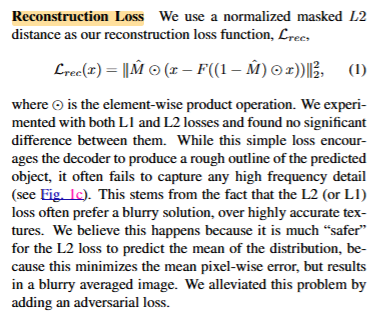

In [9]:
import torch
import torch.nn as nn

class ReconstructionLoss(nn.Module):
    """
    pred, target: (B, C, H, W)
    mask:         (B, 1, H, W), 1 = hole (region to predict), 0 = known
    """
    def __init__(self, eps=1e-8):
        super().__init__()
        self.eps = eps

    def forward(self, pred, target, mask):
        diff = mask * (target - pred) # M * (x - F(...))
        sq_err = diff.pow(2).sum(dim=(1, 2, 3)) # squared L2 norm per sample
        norm = mask.sum(dim=(1, 2, 3)) * pred.size(1) + self.eps
        return (sq_err / norm).mean()     


## Adversarial Loss

The adversarial loss is based on Generative Adversarial Networks (GAN). To learn a generative model G of a data distribution, GAN proposes to jointly learn an adversarial discriminative model D to provide loss gradients to the generative model. G and D are parametric functions (e.g., deep networks) where G : Z → Xmaps samples from noise distribution Z to data distributionX . The learning procedure is a two-player game where an adversarial discriminator D takes in both the prediction ofG and ground truth samples, and tries to distinguish them, while G tries to confuse D by producing samples that appear as “real” as possible. The objective for discriminator is logistic likelihood indicating whether the input is real sample or predicted one. 

In [10]:
# Adversarial loss consist of a generator and a discriminator
# Generator creates image, discriminator discriminate betewen real and reconstructed image
# Context encoder is our generator which generates image

import torch
import torch.nn as nn
import torch.nn.functional as F

class Discriminator(nn.Module):
    """Real (x) vs. fake (F((1-M)*x)). 3x128x128 -> single logit."""
    def __init__(self):
        super().__init__()
        def block(cin, cout, bn=True):
            layers = [nn.Conv2d(cin, cout, 4, 2, 1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            block(3,   64, bn=False),   # 128 -> 64
            block(64,  128),            # 64  -> 32
            block(128, 256),            # 32  -> 16
            block(256, 512),            # 16  -> 8
            block(512, 512),            # 8   -> 4
        )
        self.classifier = nn.Linear(512 * 4 * 4, 1)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))   # raw logit


class AdversarialLoss(nn.Module):
    """Eq. 2. D maximizes log D(x) + log(1 - D(F(...))); equivalently minimizes BCE."""
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def d_loss(self, d_real_logits, d_fake_logits):
        real = self.bce(d_real_logits, torch.ones_like(d_real_logits))
        fake = self.bce(d_fake_logits, torch.zeros_like(d_fake_logits))
        return real + fake

    def g_loss(self, d_fake_logits):
        # Minimize -log D(F(...)) instead of log(1 - D(F(...)))
        return self.bce(d_fake_logits, torch.ones_like(d_fake_logits))


class JointLoss(nn.Module):
    """Eq. 3: L = λ_rec * L_rec + λ_adv * L_adv  (generator side)."""
    def __init__(self, lambda_rec=0.999, lambda_adv=0.001):
        super().__init__()
        self.lambda_rec, self.lambda_adv = lambda_rec, lambda_adv
        self.rec = ReconstructionLoss()
        self.adv = AdversarialLoss()

    def forward(self, pred, target, mask, d_fake_logits):
        l_rec = self.rec(pred, target, mask)
        l_adv = self.adv.g_loss(d_fake_logits)
        total = self.lambda_rec * l_rec + self.lambda_adv * l_adv
        return total, l_rec, l_adv


## Training Loop

Epoch 01/20 | 84s | adv=off | D 0.000 | G 0.2032 | rec 0.2032 | adv 0.000 | val rec 0.1352 | val PSNR 25.36 dB
Epoch 02/20 | 74s | adv=off | D 0.000 | G 0.1207 | rec 0.1207 | adv 0.000 | val rec 0.1208 | val PSNR 25.70 dB


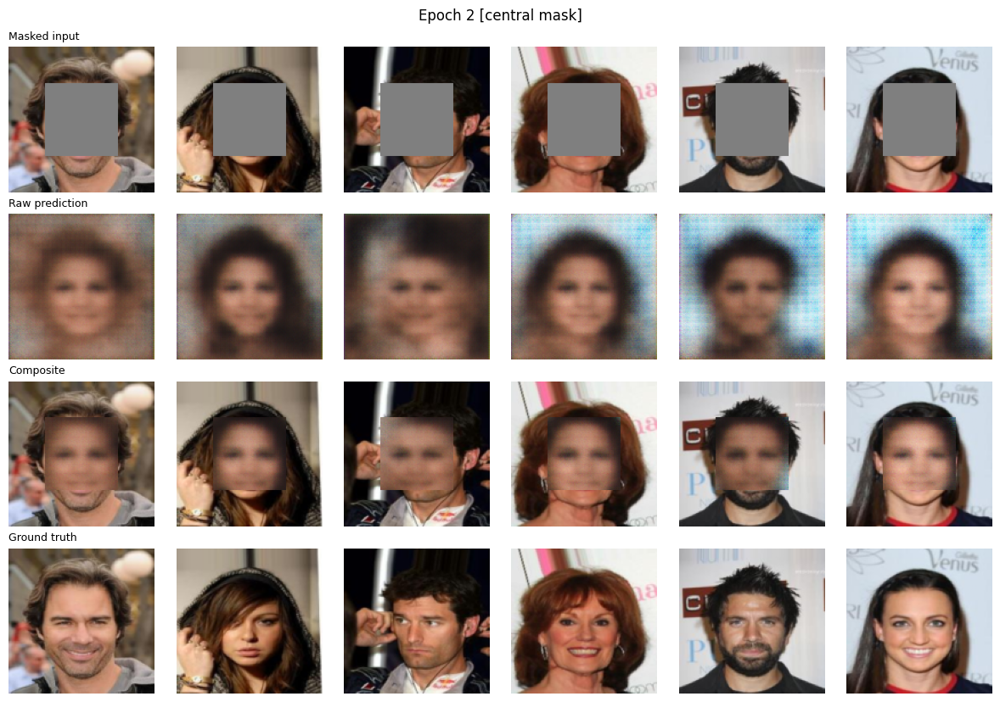

Epoch 03/20 | 112s | adv=on  | D 0.298 | G 0.1178 | rec 0.1121 | adv 5.814 | val rec 0.1203 | val PSNR 25.92 dB
Epoch 04/20 | 111s | adv=on  | D 0.165 | G 0.1081 | rec 0.1021 | adv 6.121 | val rec 0.0984 | val PSNR 26.79 dB


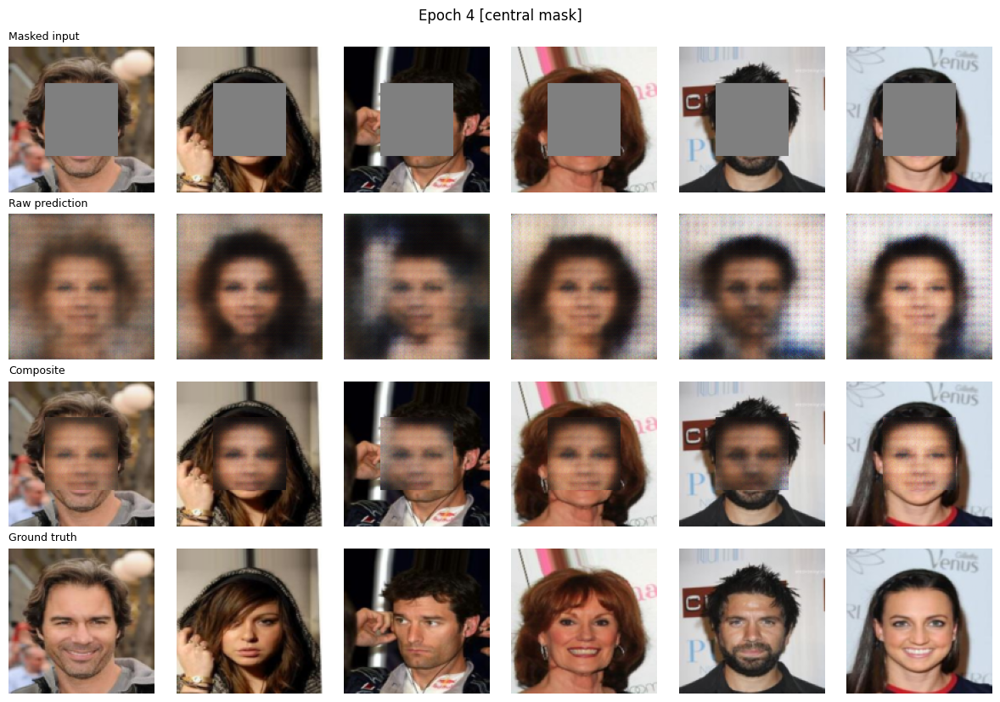

Epoch 05/20 | 106s | adv=on  | D 0.084 | G 0.1064 | rec 0.0997 | adv 6.788 | val rec 0.1049 | val PSNR 26.40 dB
Epoch 06/20 | 109s | adv=on  | D 0.132 | G 0.1054 | rec 0.0981 | adv 7.317 | val rec 0.0980 | val PSNR 26.76 dB


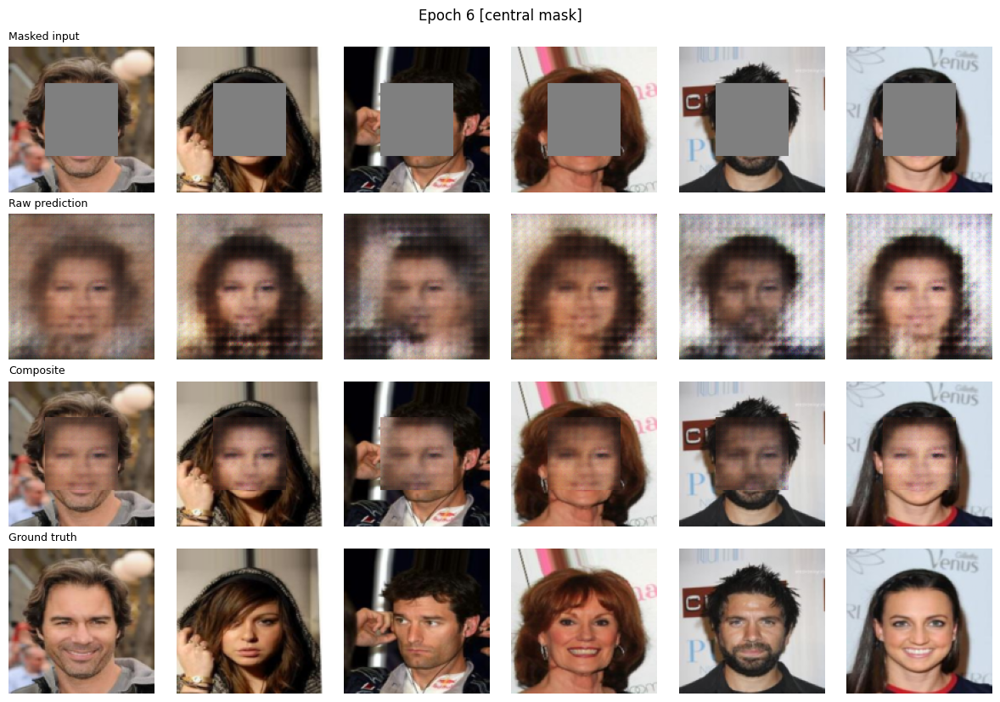

Epoch 07/20 | 105s | adv=on  | D 0.121 | G 0.1008 | rec 0.0930 | adv 7.907 | val rec 0.1009 | val PSNR 26.67 dB
Epoch 08/20 | 105s | adv=on  | D 0.186 | G 0.0989 | rec 0.0922 | adv 6.862 | val rec 0.0930 | val PSNR 27.01 dB


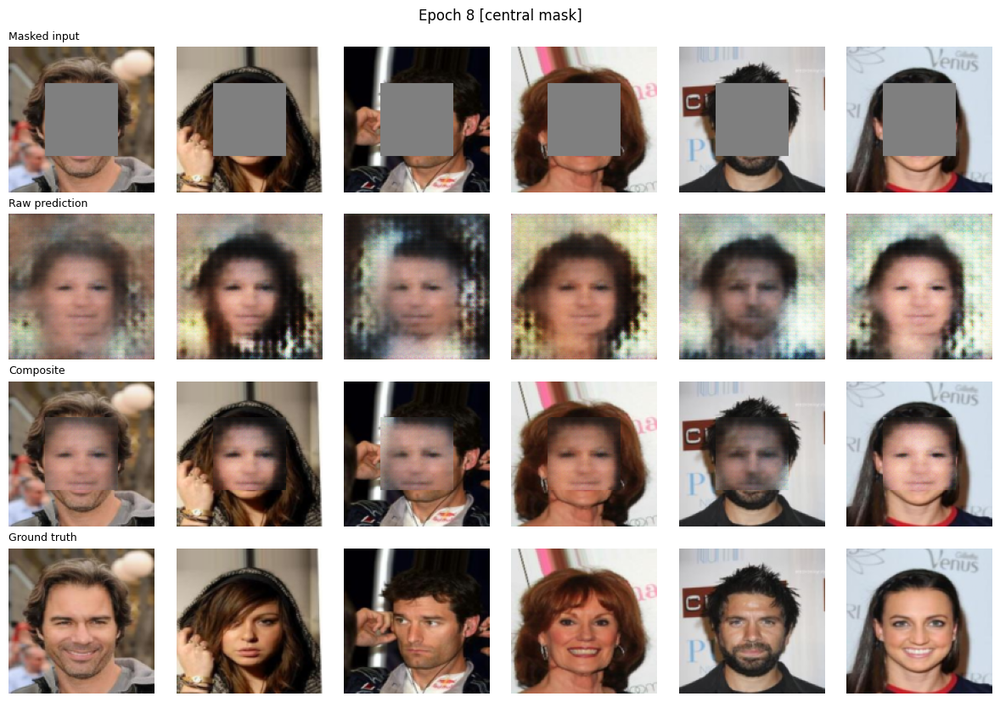

Epoch 09/20 | 102s | adv=on  | D 0.123 | G 0.0946 | rec 0.0867 | adv 7.991 | val rec 0.0866 | val PSNR 27.31 dB
Epoch 10/20 | 104s | adv=on  | D 0.122 | G 0.0942 | rec 0.0860 | adv 8.313 | val rec 0.1103 | val PSNR 26.30 dB


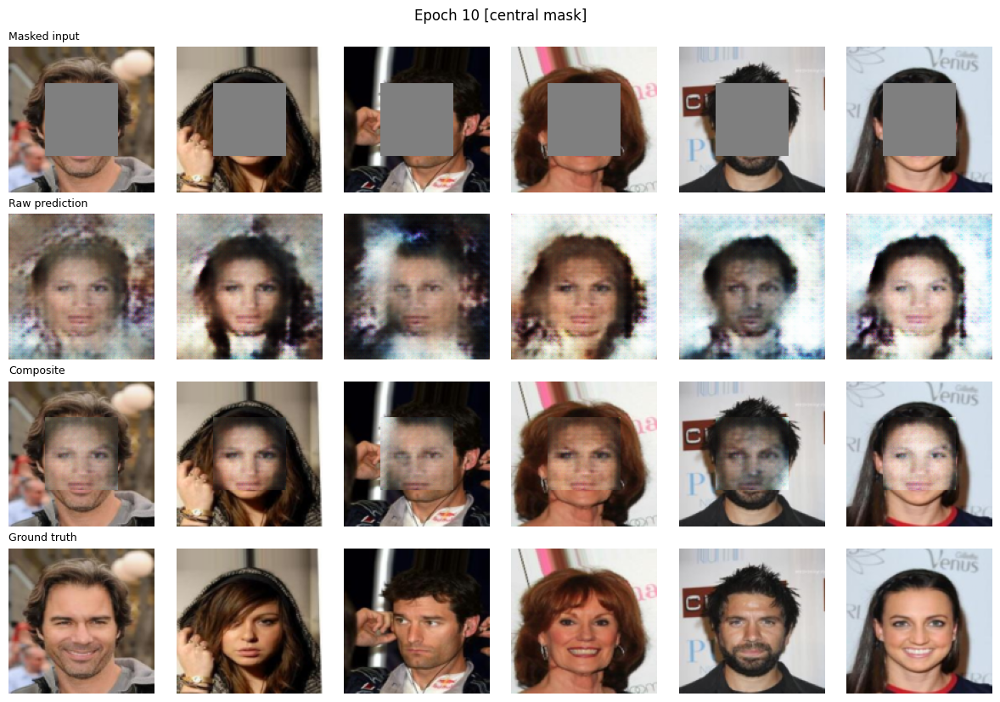

Epoch 11/20 | 102s | adv=on  | D 0.196 | G 0.0916 | rec 0.0841 | adv 7.654 | val rec 0.0917 | val PSNR 27.13 dB
Epoch 12/20 | 110s | adv=on  | D 0.098 | G 0.0943 | rec 0.0853 | adv 9.094 | val rec 0.0922 | val PSNR 27.11 dB


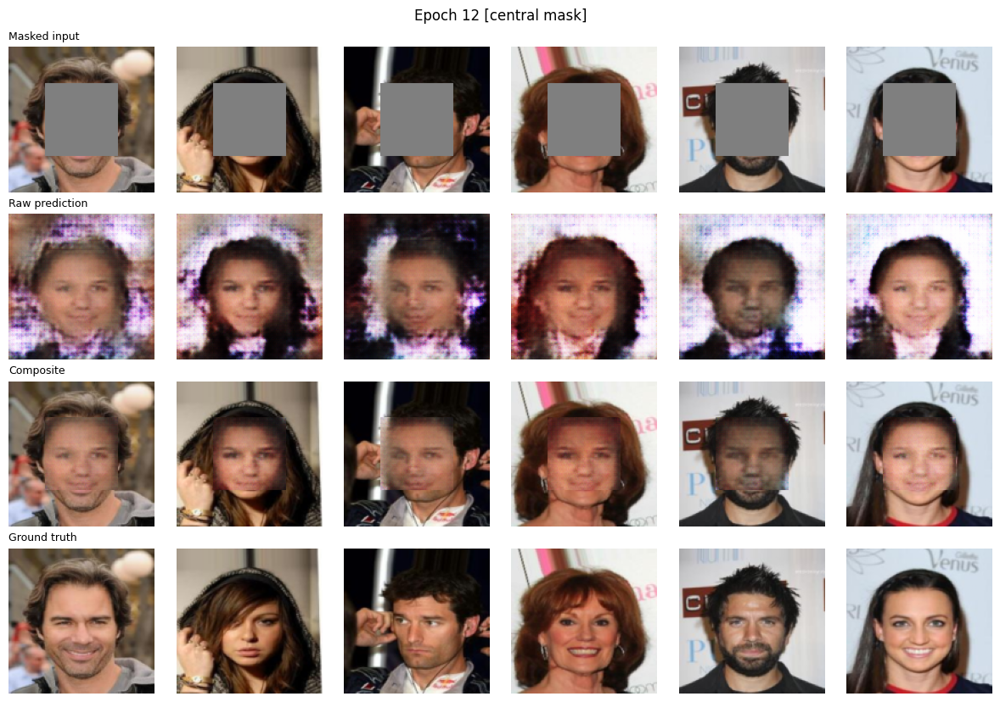

Epoch 13/20 | 108s | adv=on  | D 0.176 | G 0.0917 | rec 0.0831 | adv 8.674 | val rec 0.0939 | val PSNR 26.93 dB
Epoch 14/20 | 112s | adv=on  | D 0.187 | G 0.0906 | rec 0.0821 | adv 8.588 | val rec 0.0853 | val PSNR 27.37 dB


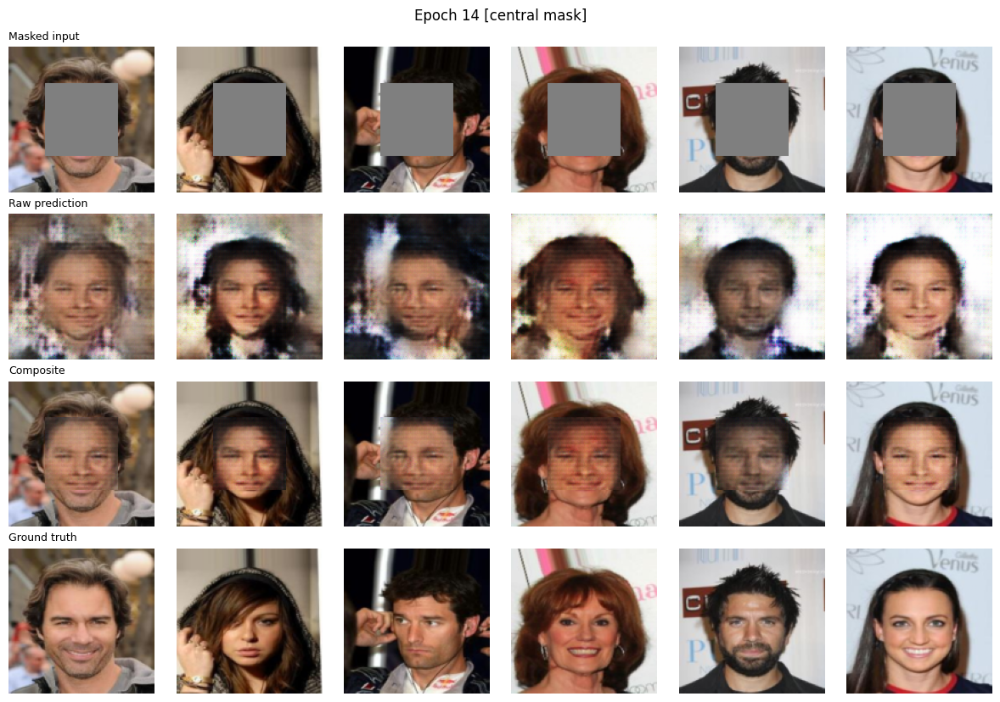

Epoch 15/20 | 111s | adv=on  | D 0.126 | G 0.0906 | rec 0.0819 | adv 8.732 | val rec 0.0864 | val PSNR 27.38 dB
Epoch 16/20 | 115s | adv=on  | D 0.138 | G 0.0881 | rec 0.0797 | adv 8.507 | val rec 0.0846 | val PSNR 27.46 dB


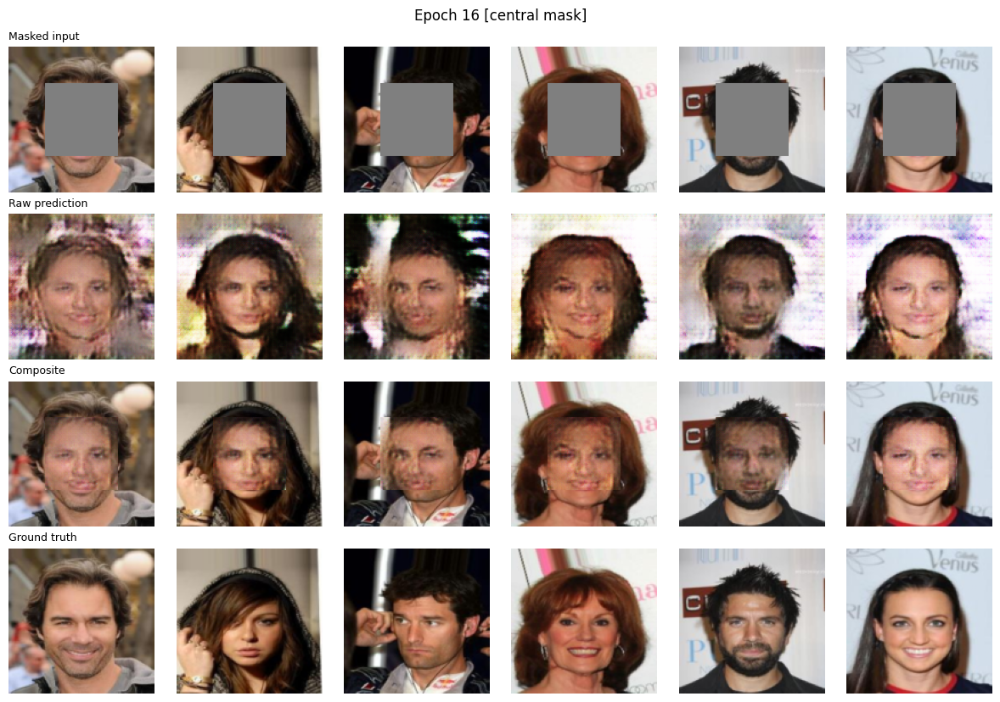

Epoch 17/20 | 111s | adv=on  | D 0.162 | G 0.0876 | rec 0.0789 | adv 8.743 | val rec 0.0817 | val PSNR 27.64 dB
Epoch 18/20 | 105s | adv=on  | D 0.171 | G 0.0868 | rec 0.0786 | adv 8.254 | val rec 0.0811 | val PSNR 27.69 dB


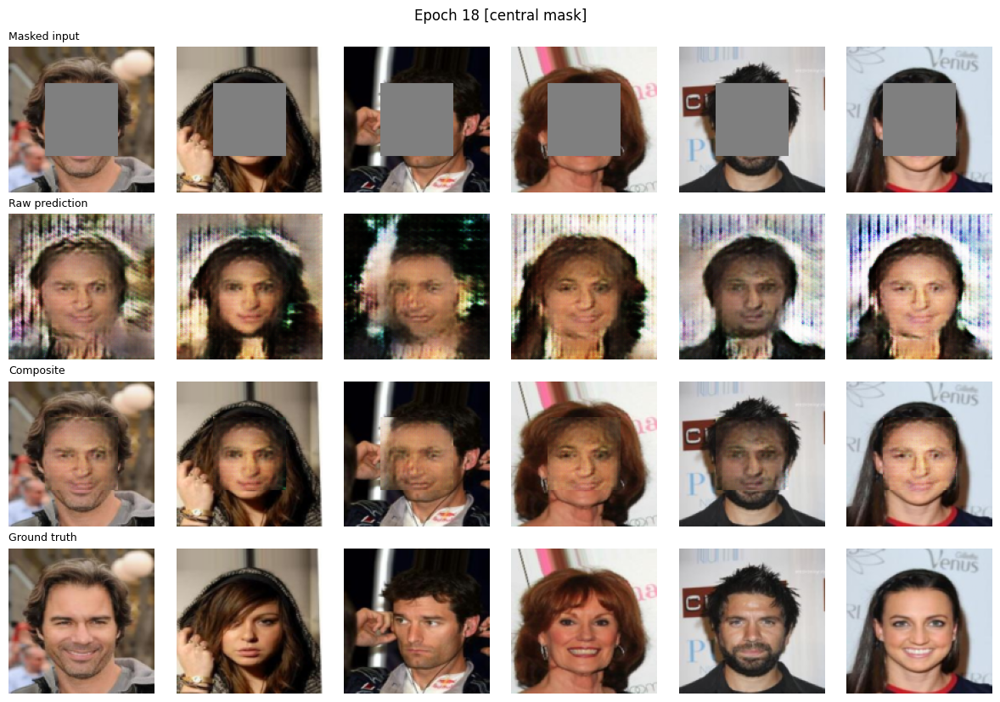

Epoch 19/20 | 104s | adv=on  | D 0.132 | G 0.0840 | rec 0.0758 | adv 8.298 | val rec 0.0792 | val PSNR 27.80 dB
Epoch 20/20 | 102s | adv=on  | D 0.204 | G 0.0847 | rec 0.0765 | adv 8.323 | val rec 0.0784 | val PSNR 27.80 dB


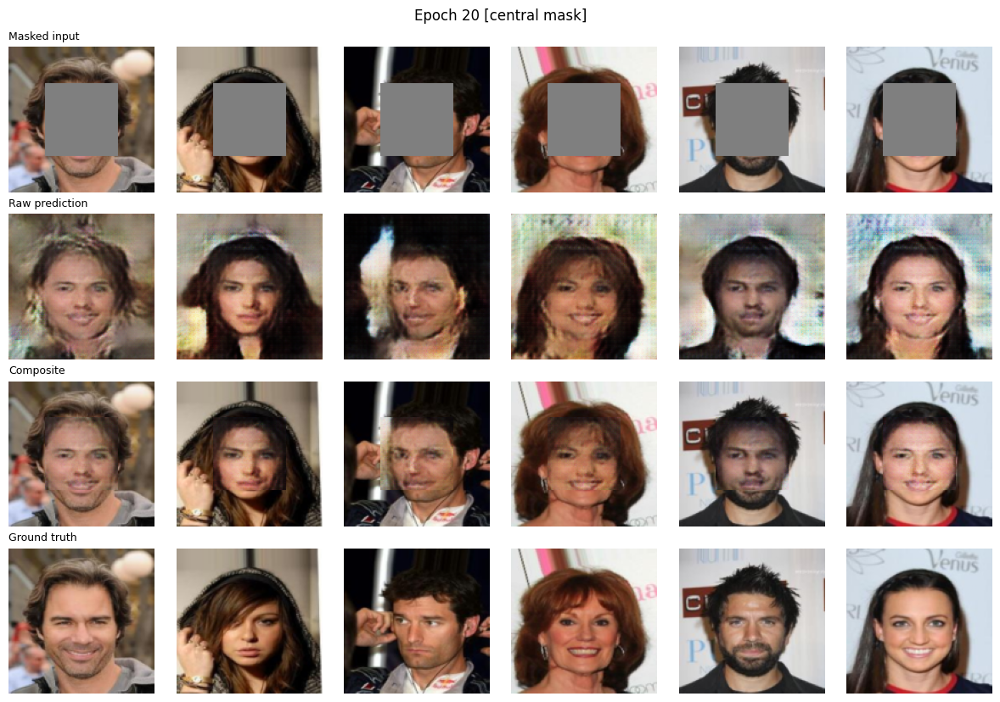

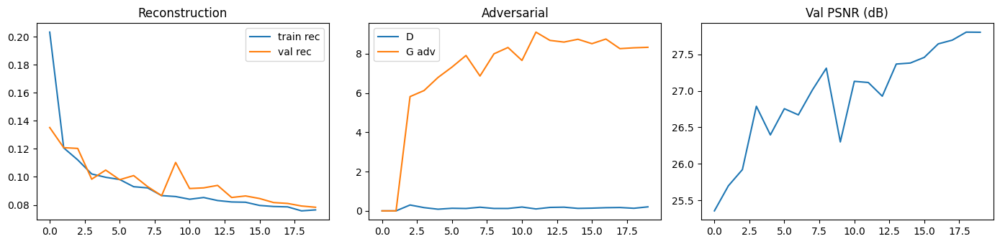

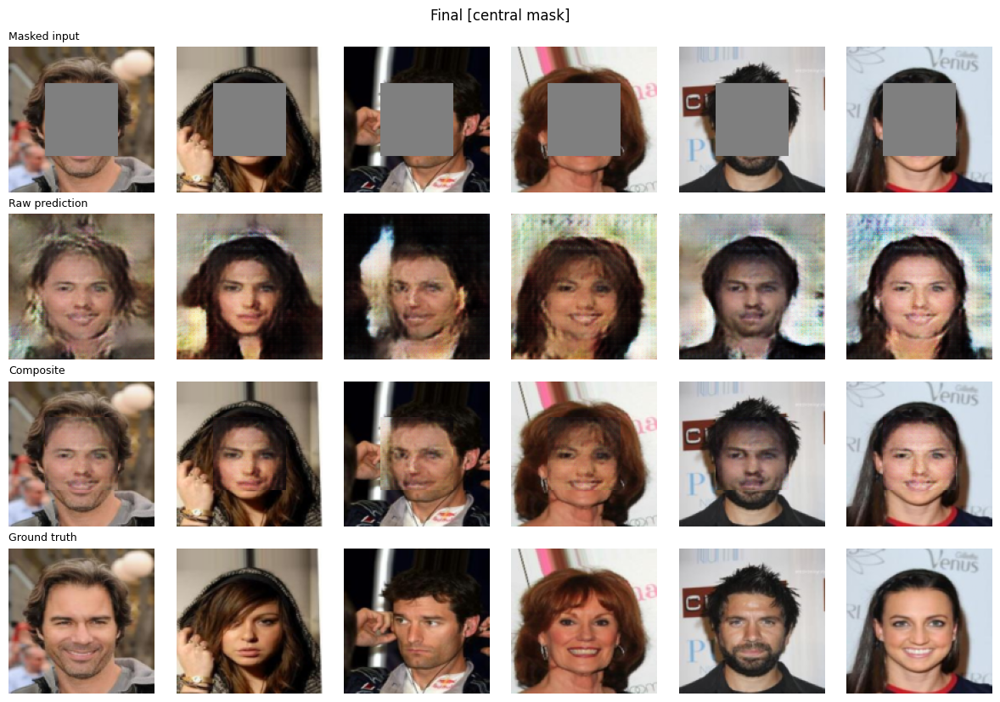

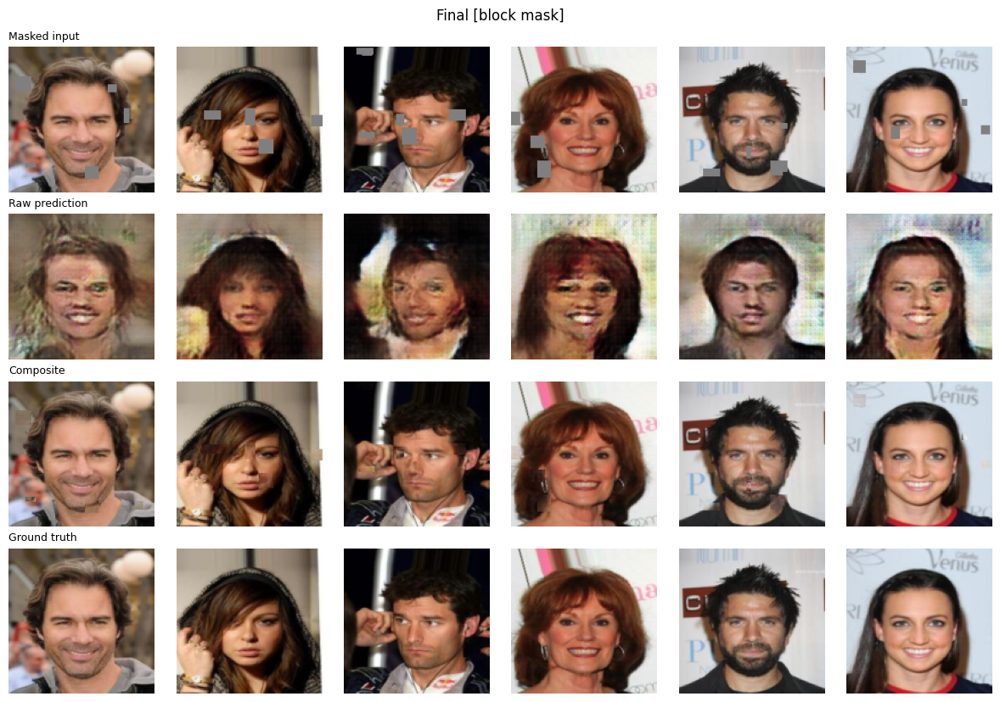

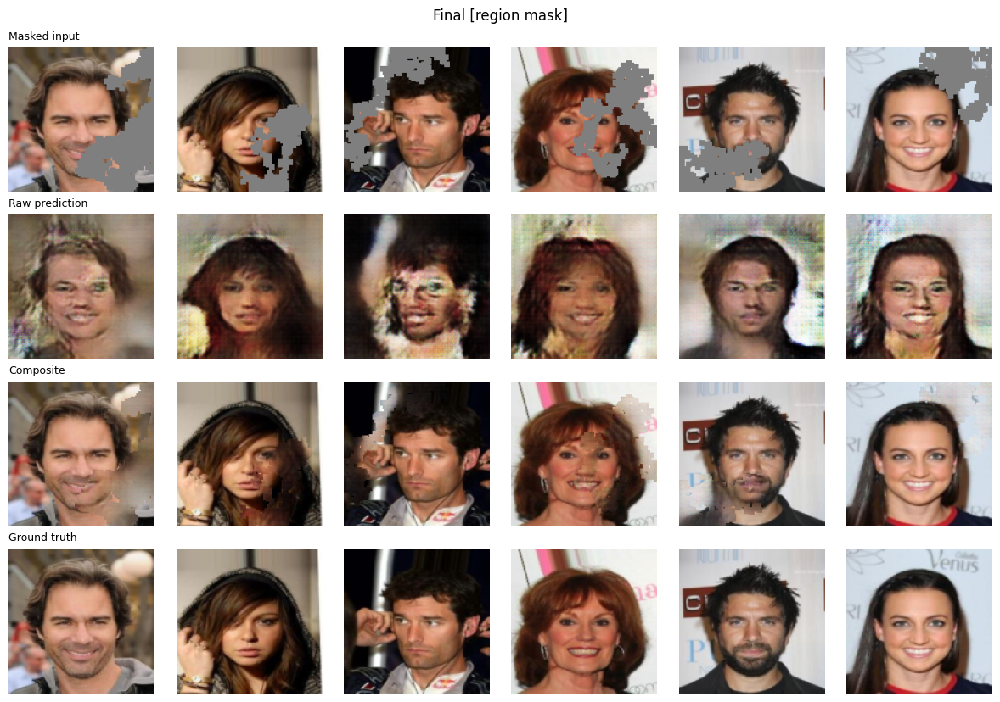

In [ ]:
import os, time
import numpy as np
import torch
import matplotlib.pyplot as plt

EPOCHS          = 20
ADV_START_EPOCH = 2        # epochs 1..2: reconstruction only, then adversarial kicks in
LAMBDA_REC      = 0.999
LAMBDA_ADV      = 0.001    # try 0.01 if outputs stay blurry
LR              = 2e-4
MASK_KINDS      = ["central", "block", "region"]   # use ["central"] for the fastest debug run
MAX_STEPS       = None     # e.g. 20 for a smoke test
VIS_EVERY       = 2
CKPT_DIR        = "/kaggle/working/ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True
torch.manual_seed(0)

MASK_FNS = {"central": mask_central, "block": mask_block, "region": mask_region}

def make_mask(rng, B, kind):
    """Returns (B,1,H,W) float tensor on device, 1 = hole."""
    return torch.from_numpy(MASK_FNS[kind](rng, B)).unsqueeze(1).to(device)

# Models, Losses, Optimizers 
G = ContextEncoder().to(device)
D = Discriminator().to(device)
joint_loss = JointLoss(LAMBDA_REC, LAMBDA_ADV).to(device)
adv_loss, rec_loss = joint_loss.adv, joint_loss.rec

opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

# Evaluation 
@torch.no_grad()
def evaluate(G, loader, kind, max_batches=8, seed=123):
    """Masked L2 on the hole + PSNR of the composite, with fixed masks (seeded)."""
    G.eval()
    rng = np.random.default_rng(seed)
    tot_rec = tot_psnr = n = 0
    for i, img in enumerate(loader):
        if i >= max_batches:
            break
        img = img.to(device)
        mask = make_mask(rng, img.size(0), kind)
        masked = img * (1 - mask)
        pred = G(masked)
        comp = masked + pred * mask
        B = img.size(0)
        tot_rec += rec_loss(pred, img, mask).item() * B
        mse01 = (((comp - img) * 0.5) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10)  # [0,1] scale
        tot_psnr += (10 * torch.log10(1 / mse01)).sum().item()
        n += B
    return tot_rec / n, tot_psnr / n

# Visualization
@torch.no_grad()
def show_samples(G, loader, kind="central", n=6, seed=7, title=""):
    G.eval()
    rng = np.random.default_rng(seed)
    img = next(iter(loader))[:n].to(device)
    mask = make_mask(rng, img.size(0), kind)
    masked = img * (1 - mask)
    pred = G(masked)
    comp = masked + pred * mask

    to01 = lambda t: (t * 0.5 + 0.5).clamp(0, 1).cpu().permute(0, 2, 3, 1).numpy()
    rows = [("Masked input", masked), ("Raw prediction", pred),
            ("Composite", comp), ("Ground truth", img)]
    fig, axes = plt.subplots(len(rows), n, figsize=(2 * n, 2.1 * len(rows)))
    for r, (name, t) in enumerate(rows):
        arr = to01(t)
        for c in range(n):
            axes[r, c].imshow(arr[c]); axes[r, c].axis("off")
        axes[r, 0].set_title(name, fontsize=9, loc="left")
    fig.suptitle(f"{title} [{kind} mask]")
    plt.tight_layout(); plt.show()

# Training
history = {"loss_D": [], "loss_G": [], "rec": [], "adv": [], "val_rec": [], "val_psnr": []}
rng = np.random.default_rng(0)

for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    use_adv = epoch > ADV_START_EPOCH
    sums = dict(loss_D=0.0, loss_G=0.0, rec=0.0, adv=0.0); steps = 0
    t0 = time.time()

    for step, img in enumerate(train_loader):
        if MAX_STEPS and step >= MAX_STEPS:
            break
        img = img.to(device, non_blocking=True)
        B = img.size(0)

        kind = MASK_KINDS[rng.integers(len(MASK_KINDS))]       # random mask type per batch
        mask = make_mask(rng, B, kind)
        masked = img * (1 - mask)
        pred = G(masked)                                       # full-size output

        if use_adv:
            # Discriminator step
            loss_D = adv_loss.d_loss(D(img), D(pred.detach()))
            opt_D.zero_grad(set_to_none=True)
            loss_D.backward()
            opt_D.step()

            # Generator step: λ_rec * L_rec + λ_adv * L_adv
            loss_G, l_rec, l_adv = joint_loss(pred, img, mask, D(pred))
        else:
            # warm-up: reconstruction only
            l_rec = rec_loss(pred, img, mask)
            loss_G = l_rec
            loss_D = l_adv = torch.zeros((), device=device)

        opt_G.zero_grad(set_to_none=True)
        loss_G.backward()
        opt_G.step()

        sums["loss_D"] += loss_D.item(); sums["loss_G"] += loss_G.item()
        sums["rec"] += l_rec.item();     sums["adv"] += l_adv.item()
        steps += 1

    for k in sums:
        history[k].append(sums[k] / steps)

    # validation on all mask types with fixed seeds
    val = {k: evaluate(G, test_loader, k) for k in MASK_KINDS}
    history["val_rec"].append(np.mean([v[0] for v in val.values()]))
    history["val_psnr"].append(np.mean([v[1] for v in val.values()]))

    print(f"Epoch {epoch:02d}/{EPOCHS} | {time.time()-t0:.0f}s | adv={'on ' if use_adv else 'off'} | "
          f"D {history['loss_D'][-1]:.3f} | G {history['loss_G'][-1]:.4f} | "
          f"rec {history['rec'][-1]:.4f} | adv {history['adv'][-1]:.3f} | "
          f"val rec {history['val_rec'][-1]:.4f} | val PSNR {history['val_psnr'][-1]:.2f} dB")

    if epoch % VIS_EVERY == 0 or epoch == EPOCHS:
        show_samples(G, test_loader, kind="central", title=f"Epoch {epoch}")

    torch.save({"G": G.state_dict(), "D": D.state_dict(), "epoch": epoch},
               f"{CKPT_DIR}/context_encoder_last.pt")

# Visualization curves 
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(history["rec"], label="train rec"); ax[0].plot(history["val_rec"], label="val rec"); ax[0].legend(); ax[0].set_title("Reconstruction")
ax[1].plot(history["loss_D"], label="D"); ax[1].plot(history["adv"], label="G adv"); ax[1].legend(); ax[1].set_title("Adversarial")
ax[2].plot(history["val_psnr"]); ax[2].set_title("Val PSNR (dB)")
plt.tight_layout(); plt.show()

# final look at every mask type
for k in MASK_KINDS:
    show_samples(G, test_loader, kind=k, title="Final")
